# Customer 360 Intelligence - Practical Machine Learning Workshop
### NileConnect | Part C - Churn Classification

## 1. Imports

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 2. Load Dataset

In [2]:
df = pd.read_csv("customer_360_ml_workshop.csv")
df.head()

,CustomerID,Age,Region,TenureMonths,ContractType,InternetType,MonthlyUsageGB,MonthlyChargeEGP,NumServices,SupportCalls6M,LatePayments12M,PaperlessBilling,AutoPay,SatisfactionScore,Future12MRevenueEGP,Churn
0,CUST-00001,22,Alexandria,23,Month-to-month,DSL,317.9,580.48,5,5,0,Yes,Yes,5.0,6287.08,Yes
1,CUST-00002,59,Upper Egypt,9,Month-to-month,4G/5G,359.3,434.36,1,1,1,No,Yes,4.0,4619.91,No
2,CUST-00003,52,Giza,21,Month-to-month,DSL,176.9,391.35,3,5,1,Yes,Yes,5.0,4512.25,No
3,CUST-00004,41,Giza,12,Month-to-month,DSL,312.5,420.40,3,2,1,No,Yes,5.0,3809.65,No
4,CUST-00005,40,Delta,21,Month-to-month,4G/5G,191.6,462.73,3,4,0,No,Yes,3.0,4731.09,No


## 3. Features and Target

In [3]:
classification_target = "Churn"

y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns=["CustomerID", "Future12MRevenueEGP", "Churn"])

print("X shape:", X.shape)
print("y shape:", y.shape)
print()
print("Classification features:")
print(list(X.columns))
print()
print("CustomerID in features:", "CustomerID" in X.columns)
print("Future12MRevenueEGP in features:", "Future12MRevenueEGP" in X.columns)
print()
print("Churn rate (y=1 means churn):", round(y.mean() * 100, 2), "%")

X shape: (3000, 13)
y shape: (3000,)

Classification features:
['Age', 'Region', 'TenureMonths', 'ContractType', 'InternetType', 'MonthlyUsageGB', 'MonthlyChargeEGP', 'NumServices', 'SupportCalls6M', 'LatePayments12M', 'PaperlessBilling', 'AutoPay', 'SatisfactionScore']

CustomerID in features: False
Future12MRevenueEGP in features: False

Churn rate (y=1 means churn): 18.13 %


## 4. Train/Test Split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print()
print("Churn rate in train set:", round(y_train.mean() * 100, 2), "%")
print("Churn rate in test set:", round(y_test.mean() * 100, 2), "%")

X_train: (2400, 13)
X_test: (600, 13)

Churn rate in train set: 18.12 %
Churn rate in test set: 18.17 %


## 5. Preprocessing Pipeline

In [5]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
preprocessor

Numeric features: ['Age', 'TenureMonths', 'MonthlyUsageGB', 'MonthlyChargeEGP', 'NumServices', 'SupportCalls6M', 'LatePayments12M', 'SatisfactionScore']
Categorical features: ['Region', 'ContractType', 'InternetType', 'PaperlessBilling', 'AutoPay']


,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


## 6. Part C - Churn Classification

In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "Naive Bayes": GaussianNB(),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}

fitted_pipelines = {}
test_probabilities = {}
results_rows = []

for name, model in models.items():
    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    cv_scores = cross_validate(pipeline, X_train, y_train, cv=skfold, scoring=scoring)

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    fitted_pipelines[name] = pipeline
    test_probabilities[name] = y_proba

    results_rows.append({
        "Model": name,
        "CV_ROC_AUC": cv_scores["test_roc_auc"].mean(),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC_AUC": roc_auc_score(y_test, y_proba)
    })

results = pd.DataFrame(results_rows)

## 7. Model Comparison Table

In [7]:
results_table = results.sort_values("ROC_AUC", ascending=False).reset_index(drop=True)
metric_cols = ["CV_ROC_AUC", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
results_table[metric_cols] = results_table[metric_cols].round(4)
results_table

,Model,CV_ROC_AUC,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.7667,0.8133,0.4595,0.1560,0.2329,0.7639
1,Naive Bayes,0.7455,0.7500,0.3742,0.5596,0.4485,0.7607
2,Gradient Boosting,0.7526,0.8083,0.4118,0.1284,0.1958,0.7324
3,Random Forest,0.7219,0.8217,0.5417,0.1193,0.1955,0.7179
4,SVM,0.7033,0.8250,0.7000,0.0642,0.1176,0.7079
5,KNN,0.6333,0.7917,0.3400,0.1560,0.2138,0.5973
6,Decision Tree,0.5763,0.7100,0.2593,0.3211,0.2869,0.5587


### Selecting a model to inspect further

In [8]:
final_model_name = results_table.loc[0, "Model"]
print("Model selected by ROC-AUC on the test set:", final_model_name)

Model selected by ROC-AUC on the test set: Logistic Regression


## 8. Confusion Matrix

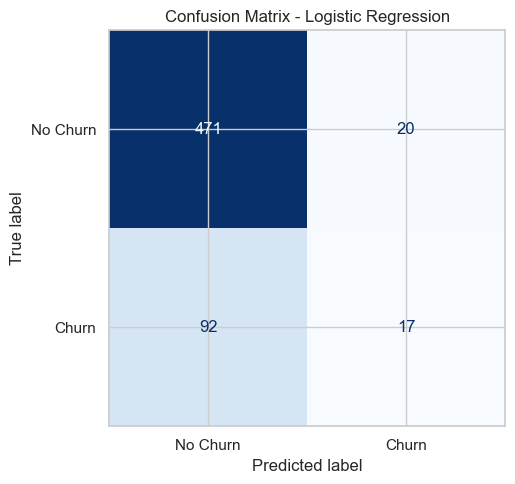

[[471  20]
 [ 92  17]]


In [9]:
final_pipeline = fitted_pipelines[final_model_name]
final_predictions = final_pipeline.predict(X_test)

cm = confusion_matrix(y_test, final_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Churn", "Churn"])

fig, ax = plt.subplots(figsize=(5.5, 5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - " + final_model_name)
plt.tight_layout()
plt.show()

print(cm)

## 9. ROC Curve

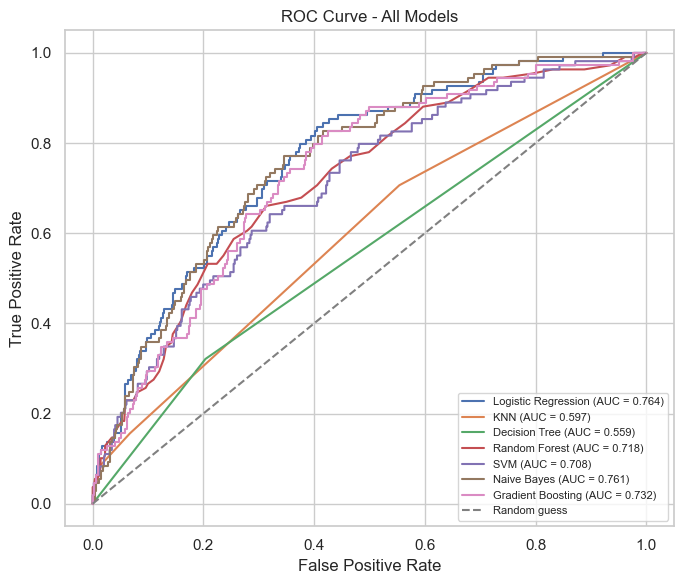

In [10]:
plt.figure(figsize=(7, 6))
for name, proba in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_value = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - All Models")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## 10. Tuning Random Forest with GridSearchCV

In [11]:
param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__class_weight": [None, "balanced"]
}

rf_pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", RandomForestClassifier(random_state=42))])

grid_search = GridSearchCV(rf_pipeline, param_grid, cv=skfold, scoring="f1", n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best parameters found:", grid_search.best_params_)
print("Best cross-validated F1 score:", round(grid_search.best_score_, 4))

Best parameters found: {'model__class_weight': 'balanced', 'model__max_depth': 5, 'model__min_samples_split': 2, 'model__n_estimators': 300}
Best cross-validated F1 score: 0.4451


### Baseline vs tuned Random Forest

In [12]:
baseline_rf = fitted_pipelines["Random Forest"]
tuned_rf = grid_search.best_estimator_

baseline_pred = baseline_rf.predict(X_test)
tuned_pred = tuned_rf.predict(X_test)
tuned_proba = tuned_rf.predict_proba(X_test)[:, 1]

rf_comparison = pd.DataFrame([
    {
        "Model": "Random Forest (baseline)",
        "Accuracy": accuracy_score(y_test, baseline_pred),
        "Precision": precision_score(y_test, baseline_pred),
        "Recall": recall_score(y_test, baseline_pred),
        "F1": f1_score(y_test, baseline_pred),
        "ROC_AUC": roc_auc_score(y_test, baseline_rf.predict_proba(X_test)[:, 1])
    },
    {
        "Model": "Random Forest (tuned)",
        "Accuracy": accuracy_score(y_test, tuned_pred),
        "Precision": precision_score(y_test, tuned_pred),
        "Recall": recall_score(y_test, tuned_pred),
        "F1": f1_score(y_test, tuned_pred),
        "ROC_AUC": roc_auc_score(y_test, tuned_proba)
    }
])
rf_comparison.set_index("Model").round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Random Forest (baseline),0.8217,0.5417,0.1193,0.1955,0.7179
Random Forest (tuned),0.6833,0.3333,0.7431,0.4602,0.7540


### Confusion matrix of the tuned Random Forest

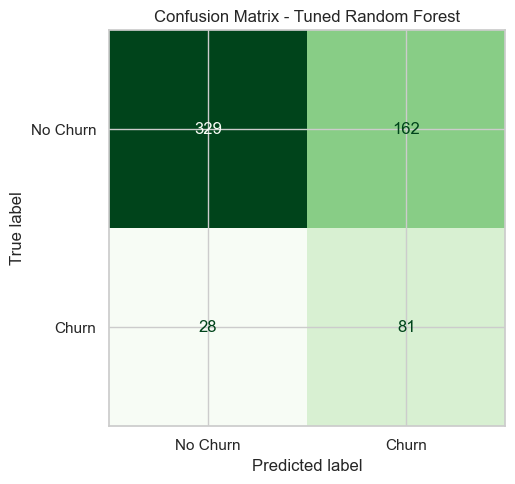

[[329 162]
 [ 28  81]]


In [13]:
cm_tuned = confusion_matrix(y_test, tuned_pred)
disp_tuned = ConfusionMatrixDisplay(confusion_matrix=cm_tuned, display_labels=["No Churn", "Churn"])

fig, ax = plt.subplots(figsize=(5.5, 5))
disp_tuned.plot(ax=ax, cmap="Greens", colorbar=False)
ax.set_title("Confusion Matrix - Tuned Random Forest")
plt.tight_layout()
plt.show()

print(cm_tuned)

## 11. Important Churn Predictors

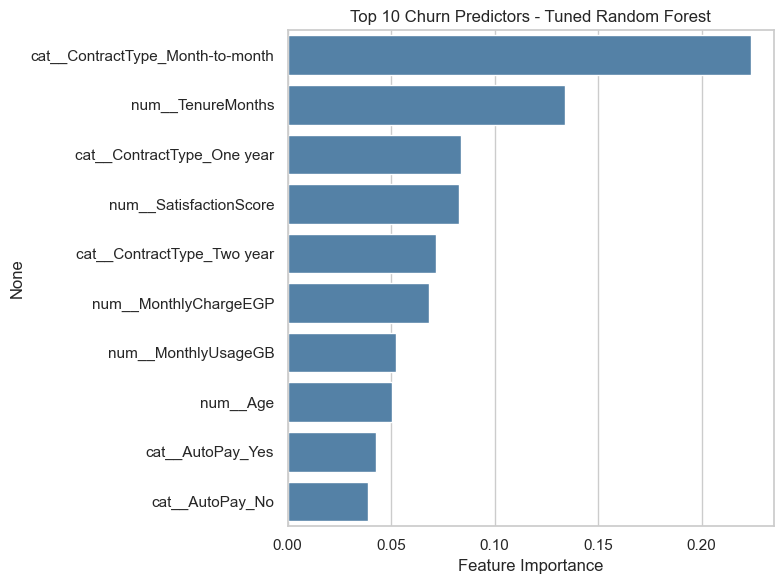

cat__ContractType_Month-to-month    0.2237
num__TenureMonths                   0.1338
cat__ContractType_One year          0.0837
num__SatisfactionScore              0.0826
cat__ContractType_Two year          0.0717
num__MonthlyChargeEGP               0.0684
num__MonthlyUsageGB                 0.0524
num__Age                            0.0505
cat__AutoPay_Yes                    0.0428
cat__AutoPay_No                     0.0388
dtype: float64

In [14]:
tuned_feature_names = tuned_rf.named_steps["preprocessor"].get_feature_names_out()
tuned_importances = tuned_rf.named_steps["model"].feature_importances_

importance_table = pd.Series(tuned_importances, index=tuned_feature_names).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x=importance_table.head(10).values, y=importance_table.head(10).index, color="steelblue")
plt.title("Top 10 Churn Predictors - Tuned Random Forest")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

importance_table.head(10).round(4)

## 12. Final Interpretation

### Baseline model comparison (test set)

| Model | CV ROC-AUC | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.7667 | 0.8133 | 0.4595 | 0.1560 | 0.2329 | 0.7639 |
| Naive Bayes | 0.7455 | 0.7500 | 0.3742 | 0.5596 | 0.4485 | 0.7607 |
| Gradient Boosting | 0.7526 | 0.8083 | 0.4118 | 0.1284 | 0.1958 | 0.7324 |
| Random Forest | 0.7219 | 0.8217 | 0.5417 | 0.1193 | 0.1955 | 0.7179 |
| SVM | 0.7033 | 0.8250 | 0.7000 | 0.0642 | 0.1176 | 0.7079 |
| KNN | 0.6333 | 0.7917 | 0.3400 | 0.1560 | 0.2138 | 0.5973 |
| Decision Tree | 0.5763 | 0.7100 | 0.2593 | 0.3211 | 0.2869 | 0.5587 |

**Logistic Regression has the highest ROC-AUC** (0.7639 on the test set, 0.7667 in cross-validation), meaning it separates churners from non-churners best across all thresholds. **Naive Bayes is a close second** (0.7607) and, at the default 0.5 threshold, actually catches far more real churners (Recall 0.5596 vs 0.1560).

### The accuracy trap, visible in this table

Every model except Naive Bayes and Decision Tree has **Recall below 0.16** at the default threshold, even though most of them show 80%+ accuracy. SVM is the clearest example: 82.5% accuracy but only 6.4% of churners caught. This happens because churn is imbalanced (about 18% of customers) - a model can score well on accuracy by mostly predicting "No churn" and still miss almost every customer about to leave, which is exactly why accuracy alone is not enough for this business problem (see Part A, Q3).

### Why Random Forest was tuned, and what changed

The baseline Random Forest reached 0.8217 accuracy but a Recall of only 0.1193 - out of 109 churners in the test set, it found roughly 13. `GridSearchCV` was used to search `n_estimators`, `max_depth`, `min_samples_split` and `class_weight`, optimizing for **F1-score** (which balances precision and recall) instead of accuracy.

**Best parameters found:** `max_depth=5`, `min_samples_split=2`, `n_estimators=300`, `class_weight="balanced"`.

| Random Forest | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Baseline | 0.8217 | 0.5417 | 0.1193 | 0.1955 | 0.7179 |
| Tuned | 0.6833 | 0.3333 | 0.7431 | 0.4602 | 0.7540 |

Tuning moved Random Forest from catching about 12% of churners to about 74% of them. The cost is accuracy, which drops from 82% to 68%, and precision, which drops from 54% to 33% (meaning more loyal customers get wrongly flagged). `class_weight="balanced"` is the main reason for the shift - it forces the model to pay as much attention to the rare churn class as to the majority class. **ROC-AUC also improved (0.7179 -> 0.7540)**, confirming the tuned model separates the two classes better overall, not only at one threshold.

### Business meaning

- From a business perspective, **missing a churner (false negative) usually costs more** than contacting a customer who was not actually going to leave (false positive) - a false negative is lost revenue with no chance to intervene, while a false positive just means an unnecessary retention offer. This makes the tuned Random Forest, with its much higher recall, the more useful model for a retention campaign, even though its plain accuracy is lower.
- **The main churn predictors are ContractType (especially Month-to-month), TenureMonths, SatisfactionScore, and the other ContractType categories**, followed by MonthlyChargeEGP and MonthlyUsageGB. This matches the EDA findings from Part A: month-to-month customers churn far more (26.61%) than one-year (8.72%) or two-year (5.14%) customers, and churners had lower tenure (20.59 vs 26.64 months) and lower satisfaction (3.14 vs 3.56).
- **Practical use:** flag customers on month-to-month contracts, with short tenure and low satisfaction, for proactive retention outreach (offers to move to longer contracts, or a check-in call), since these are the strongest signals the data shows for churn risk.
- All numbers above come from a single 80/20 split and default or grid-searched settings; a production system would also check stability across several splits and consider the cost of each type of error explicitly before choosing a final threshold.

## 13. Final Checklist

**Part C - Churn Classification**
- [x] `CustomerID` and `Future12MRevenueEGP` removed from the classification features
- [x] Stratified 80/20 train/test split with `random_state=42`
- [x] Same reusable preprocessing pipeline (median imputation + StandardScaler for numerical, most-frequent imputation + OneHotEncoder for categorical), fitted on training data only
- [x] Seven models compared: Logistic Regression, KNN, Decision Tree, Random Forest, SVM, Naive Bayes, Gradient Boosting
- [x] Accuracy, Precision, Recall, F1 and ROC-AUC reported in a comparison table
- [x] Confusion matrix plotted
- [x] ROC curve plotted
- [x] Random Forest tuned with `GridSearchCV`
- [x] Important churn predictors identified from the tuned Random Forest